# Embeddings and within-party groups

Roadmap step 2, part 2. This checks notebook 02 with a different method:

1. Each Congress is embedded in two dimensions by **classical multidimensional scaling** of 1 minus pairwise agreement. Votes aren't imputed. Member pairs with fewer than 20 shared votes, about 1% of pairs on average, get the mean distance, which pulls members who served only briefly slightly toward the centre.
2. Members are clustered with a **Gaussian mixture**, choosing between 1 and 5 components by BIC, and with **HDBSCAN**, which can leave members unassigned as noise. The smallest HDBSCAN cluster is 5% of the chamber.
3. Each party is embedded and clustered on its own, choosing between 1 and 3 components.

Embeddings are fitted separately for each Congress, so their axes aren't comparable across Congresses. Only measures that don't depend on the scale are compared over time: number of clusters, adjusted Rand index with party, purity and noise share.

Scope and cutoffs match notebooks 01 and 02.

In [1]:
import os
import sys
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "8")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_rand_score

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from clustering import SOUTH, agreement_matrix, choose_mixture, classical_mds
from voteview import build_matrix, load_members, load_rollcalls, load_votes

warnings.filterwarnings("ignore", category=UserWarning)
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

INCOMPLETE_CONGRESS = 119
MIN_PARTY_MEMBERS = 10
CHAMBERS = ["House", "Senate"]


def first_year(congress):
    return 1789 + 2 * (congress - 1)


members = load_members()
rollcalls = load_rollcalls()
votes = load_votes()
voting_members = members[~members["is_delegate"]]
counts = voting_members.groupby(["congress", "chamber"])["party"].value_counts().unstack(fill_value=0)
selected = counts[(counts["D"] >= MIN_PARTY_MEMBERS) & (counts["R"] >= MIN_PARTY_MEMBERS)].index
info = members.drop_duplicates(["congress", "chamber", "icpsr"]).set_index(["congress", "chamber", "icpsr"])
info["south"] = info["state_abbrev"].isin(SOUTH)
votes_by, rollcalls_by, members_by = (frame.groupby(["congress", "chamber"]) for frame in (votes, rollcalls, members))
print(len(selected), "Congress and chamber combinations")


170 Congress and chamber combinations


## Embedding and clustering each Congress

In [2]:
def ari(labels, reference):
    return adjusted_rand_score(reference, labels) if len(set(labels)) > 1 else 0.0


def purity(labels, party):
    table = pd.crosstab(labels, party)
    return table.max(axis=1).sum() / table.to_numpy().sum()


SUBSAMPLE = 250
KEEP = {(91, "House"), (110, "House"), (115, "House"), (118, "House"), (110, "Senate"), (118, "Senate")}
rng = np.random.default_rng(0)
rows, maps, kept_agreements = [], {}, {}
for key in selected:
    matrix = build_matrix(votes_by.get_group(key), rollcalls_by.get_group(key), members_by.get_group(key))
    people = info.loc[key].reindex(matrix.index)
    agreement = agreement_matrix(matrix)
    if key in KEEP:
        kept_agreements[key] = agreement
    coordinates, kept = classical_mds(agreement)
    if matrix.shape[1] >= SUBSAMPLE:
        sample = matrix.iloc[:, rng.choice(matrix.shape[1], SUBSAMPLE, replace=False)]
        kept_subsample = classical_mds(agreement_matrix(sample))[1]
    else:
        kept_subsample = np.nan
    if coordinates.loc[people["party"] == "R", "dim1"].mean() < coordinates.loc[people["party"] == "D", "dim1"].mean():
        coordinates["dim1"] *= -1
    two_party = people["party"].isin(["D", "R"]).to_numpy()
    party = people["party"].to_numpy()[two_party]
    points = coordinates.to_numpy()

    components, mixture = choose_mixture(points, 5)
    density = HDBSCAN(min_cluster_size=max(5, int(0.05 * len(points)))).fit_predict(points)
    clustered = density >= 0
    pairs = len(agreement) * (len(agreement) - 1)
    row = {
        "congress": key[0], "chamber": key[1], "members": len(points), "rollcalls": matrix.shape[1],
        "missing_pairs": (agreement.isna().to_numpy().sum() - len(agreement)) / pairs,
        "variance_kept": kept, "variance_kept_250": kept_subsample,
        "mixture_components": components, "mixture_party_ari": ari(mixture[two_party], party),
        "mixture_purity": purity(mixture[two_party], party),
        "density_clusters": len(set(density[clustered])), "density_noise": 1 - clustered.mean(),
        "density_party_ari": ari(density[two_party & clustered], people["party"].to_numpy()[two_party & clustered]),
        "density_party_ari_all": ari(density[two_party], party),
    }
    for name in ["D", "R"]:
        mask = (people["party"] == name).to_numpy()
        inner, _ = classical_mds(agreement.loc[mask, mask])
        groups, assigned = choose_mixture(inner.to_numpy(), 3)
        south = people["south"].to_numpy()[mask]
        shares = pd.Series(south).groupby(assigned).mean()
        sizes = pd.Series(assigned).value_counts(normalize=True)
        big = sizes[sizes >= 0.10].index
        row[f"{name}_factions"] = len(big)
        row[f"{name}_south_gap"] = shares[big].max() - shares[big].min() if len(big) >= 2 else np.nan
    rows.append(row)
    maps[key] = coordinates.join(people[["party", "south", "bioname"]])

embeddings = pd.DataFrame(rows)
embeddings["year"] = first_year(embeddings["congress"])
complete = embeddings[embeddings["congress"] < INCOMPLETE_CONGRESS]
print("Share of member pairs with fewer than 20 shared votes, given the mean distance in MDS:")
print(embeddings["missing_pairs"].describe().round(4).to_dict())
display(embeddings[embeddings["congress"].isin([60, 80, 90, 91, 95, 100, 105, 110, 115, 118])].set_index(["chamber", "congress"]).sort_index().round(3))


Share of member pairs with fewer than 20 shared votes, given the mean distance in MDS:
{'count': 170.0, 'mean': 0.0114, 'std': 0.0201, 'min': 0.0, '25%': 0.0008, '50%': 0.0034, '75%': 0.0138, 'max': 0.151}


members  rollcalls  missing_pairs  variance_kept  \
chamber congress                                                     
House   60            387        231          0.036          0.468   
        80            447        147          0.007          0.507   
        90            437        390          0.001          0.566   
        91            442        354          0.002          0.449   
        95            437       1217          0.000          0.556   
        100           439        770          0.000          0.684   
        105           442        946          0.001          0.711   
        110           446       1387          0.001          0.854   
        115           445        958          0.003          0.858   
        118           445       1119          0.001          0.875   
Senate  60             92         79          0.151          0.455   
        80             97        237          0.000          0.676   
        90            101        518          0.003          0.570   
        91            102        557          0.001          0.629   
        95            104       1039          0.002          0.598   
        100           101        635          0.004          0.670   
        105           100        486          0.000          0.794   
        110           102        550          0.001          0.812   
        115           104        522          0.003          0.899   
        118           104        659          0.004          0.889   

                  variance_kept_250  mixture_components  mixture_party_ari  \
chamber congress                                                             
House   60                      NaN                   4              0.714   
        80                      NaN                   4              0.555   
        90                    0.546                   3              0.704   
        91                    0.429                   4              0.493   
        95                    0.470                   4              0.408   
        100                   0.610                   4              0.468   
        105                   0.652                   4              0.562   
        110                   0.792                   5              0.597   
        115                   0.871                   5              0.461   
        118                   0.863                   5              0.546   
Senate  60                      NaN                   3              0.544   
        80                      NaN                   4              0.660   
        90                    0.551                   3              0.597   
        91                    0.586                   3              0.721   
        95                    0.540                   3              0.187   
        100                   0.653                   2              1.000   
        105                   0.766                   3              0.788   
        110                   0.773                   4              0.543   
        115                   0.882                   4              0.924   
        118                   0.891                   4              0.848   

                  mixture_purity  density_clusters  density_noise  \
chamber congress                                                    
House   60                 1.000                 2          0.016   
        80                 0.998                 2          0.038   
        90                 0.995                 3          0.181   
        91                 0.955                 3          0.253   
        95                 0.924                 2          0.286   
        100                0.975                 2          0.077   
        105                0.998                 2          0.009   
        110                1.000                 2          0.016   
        115                0.989                 3          0.106   
 

Two dimensions keep a growing share of the structure: about half before 1980, and 84% in the House and 87% in the Senate from 2001 to 2023.

Recent Congresses have more roll calls, which could raise this by reducing noise. With every Congress cut to a random 250 roll calls, the rise remains: House 49% (1937 to 1979) to 80% (2001 to 2023), and Senate 61% to 86%.

The Gaussian mixture usually picks 4 or 5 components. The checks below explain why.

## Maps of three Congresses

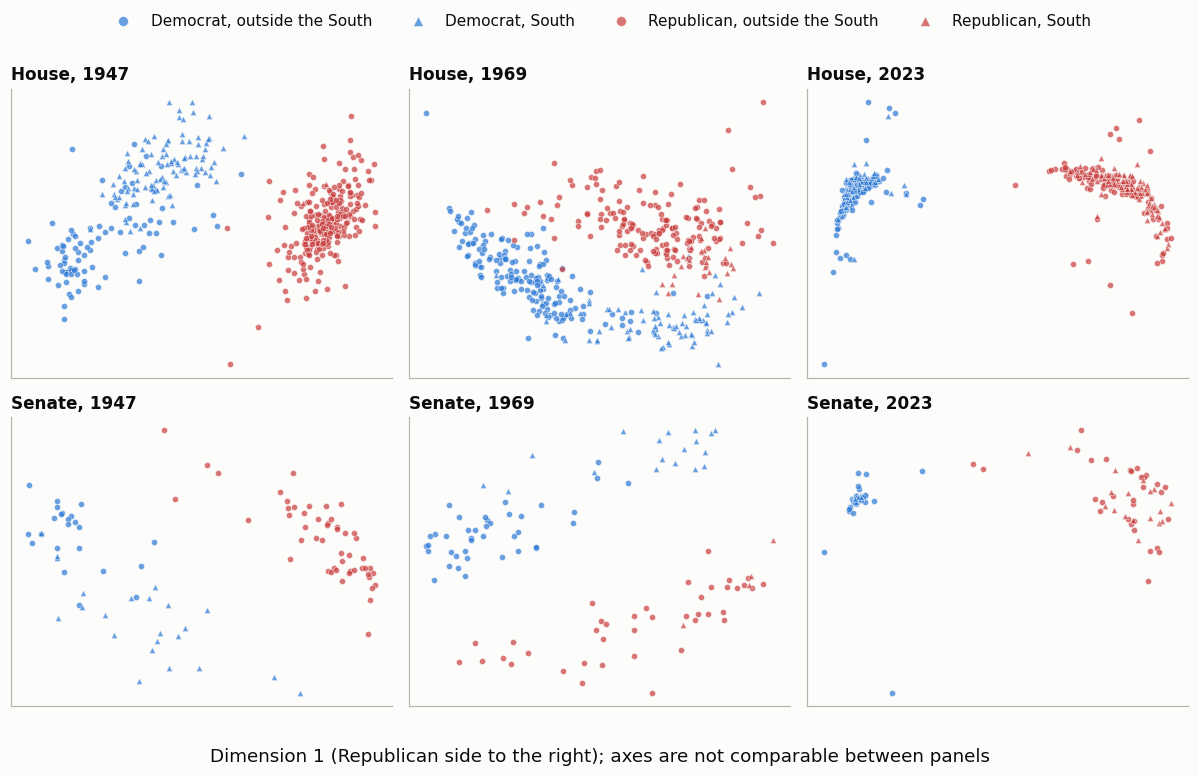

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for row, chamber in enumerate(CHAMBERS):
    for column, congress in enumerate([80, 91, 118]):
        axis = axes[row, column]
        frame = maps[(congress, chamber)]
        for party in ["D", "R"]:
            for south, marker, label in [(False, "o", "outside the South"), (True, "^", "South")]:
                part = frame[(frame["party"] == party) & (frame["south"] == south)]
                name = "Democrat" if party == "D" else "Republican"
                axis.scatter(part["dim1"], part["dim2"], s=16, marker=marker, color=COLORS[party], alpha=0.7,
                             edgecolors="#fcfcfb", linewidths=0.4, label=f"{name}, {label}")
        axis.set_title(f"{chamber}, {first_year(congress)}")
        axis.set_xticks([])
        axis.set_yticks([])
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=4, markerscale=1.6)
fig.supxlabel("Dimension 1 (Republican side to the right); axes are not comparable between panels")
fig.tight_layout(rect=(0, 0.02, 1, 0.94))
plt.show()


**What the maps show**

- **2023:** each chamber has two tight, separate party clusters with nothing between them.
- **House 1969:** there is no gap between the parties, and Southern Democrats (triangles) spread from the Democratic side into the Republican cluster. Measured directly from agreement, not from the map, 78% of the 80 Southern Democrats agreed more with Republicans than with non-Southern Democrats on average. Their median agreement was 0.665 with Republicans and 0.567 with non-Southern Democrats.
- **1947:** the parties are separate, but Southern Democrats form a distinct arm of the Democratic cluster, especially in the House. The group existed before it crossed over.

The 2D maps keep only about half of the structure for mid-century Congresses, so read them as illustrations. The agreement figures above carry the evidence.

## Clusters and within-party groups over time

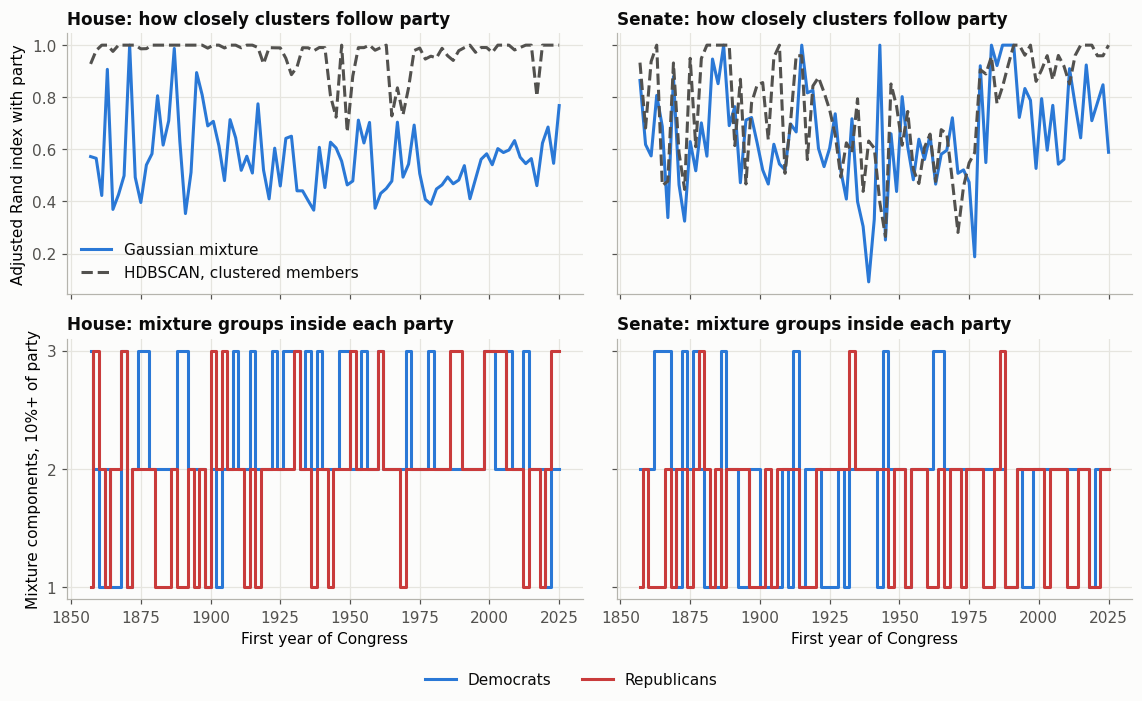

chamber                    House                                          \
year                   1857-1899 1901-1935 1937-1979 1981-1999 2001-2023   
rollcalls                405.318   176.000   373.000   851.400  1008.333   
variance_kept              0.508     0.448     0.524     0.669     0.840   
variance_kept_250          0.481     0.403     0.489     0.604     0.804   
mixture_components         3.864     4.111     4.091     4.400     4.833   
mixture_party_ari          0.626     0.561     0.530     0.493     0.580   
mixture_purity             0.992     0.983     0.981     0.978     0.995   
density_clusters           2.000     2.056     2.318     2.000     2.083   
density_noise              0.027     0.055     0.126     0.090     0.018   
density_party_ari          0.993     0.978     0.909     0.976     0.979   
density_party_ari_all      0.956     0.890     0.723     0.835     0.948   
d_two_or_more_factions     0.773     0.944     1.000     1.000     0.917   
r_two_or_more_factions     0.545     0.889     0.864     1.000     0.833   
d_south_gap                0.482     0.506     0.713     0.295     0.140   
r_south_gap                0.145     0.026     0.096     0.197     0.242   

chamber                   Senate                                          
year                   1857-1899 1901-1935 1937-1979 1981-1999 2001-2023  
rollcalls                529.773   290.167   471.818   615.100   566.583  
variance_kept              0.582     0.562     0.617     0.707     0.870  
variance_kept_250          0.552     0.545     0.606     0.674     0.855  
mixture_components         3.227     3.056     3.091     2.900     4.000  
mixture_party_ari          0.671     0.622     0.536     0.834     0.738  
mixture_purity             0.967     0.950     0.933     0.991     0.982  
density_clusters           2.727     2.778     4.364     2.600     2.417  
density_noise              0.100     0.107     0.189     0.067     0.043  
density_party_ari          0.797     0.755     0.575     0.921     0.945  
density_party_ari_all      0.671     0.622     0.400     0.828     0.882  
d_two_or_more_factions     0.727     0.444     0.909     0.600     0.917  
r_two_or_more_factions     0.545     0.722     0.727     0.600     0.583  
d_south_gap                0.301     0.173     0.585     0.359     0.261  
r_south_gap                0.115     0.002     0.072     0.208     0.249

Complete Congresses where the mixture found exactly the two parties (ARI 0.95 or more):
{'count': {'House': 2, 'Senate': 7}, 'min': {'House': 1871, 'Senate': 1887}}


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True, sharey="row")
for column, chamber in enumerate(CHAMBERS):
    data = embeddings[embeddings["chamber"] == chamber]
    axes[0, column].plot(data["year"], data["mixture_party_ari"], color=COLORS["D"], label="Gaussian mixture")
    axes[0, column].plot(data["year"], data["density_party_ari"], color=NEUTRAL, linestyle="--", label="HDBSCAN, clustered members")
    axes[0, column].set_title(f"{chamber}: how closely clusters follow party")
    for party, name in [("D", "Democrats"), ("R", "Republicans")]:
        axes[1, column].step(data["year"], data[f"{party}_factions"], where="mid", color=COLORS[party], label=name)
    axes[1, column].set_title(f"{chamber}: mixture groups inside each party")
    axes[1, column].set_xlabel("First year of Congress")
axes[0, 0].set_ylabel("Adjusted Rand index with party")
axes[1, 0].set_ylabel("Mixture components, 10%+ of party")
axes[1, 0].set_yticks([1, 2, 3])
axes[0, 0].legend(loc="lower left")
handles, legend_labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

summary = complete.groupby(["chamber", pd.cut(complete["year"], [1856, 1900, 1936, 1980, 2000, 2024], labels=["1857-1899", "1901-1935", "1937-1979", "1981-1999", "2001-2023"])], observed=True).agg(
    rollcalls=("rollcalls", "mean"),
    variance_kept=("variance_kept", "mean"),
    variance_kept_250=("variance_kept_250", "mean"),
    mixture_components=("mixture_components", "mean"),
    mixture_party_ari=("mixture_party_ari", "mean"),
    mixture_purity=("mixture_purity", "mean"),
    density_clusters=("density_clusters", "mean"),
    density_noise=("density_noise", "mean"),
    density_party_ari=("density_party_ari", "mean"),
    density_party_ari_all=("density_party_ari_all", "mean"),
    d_two_or_more_factions=("D_factions", lambda s: (s >= 2).mean()),
    r_two_or_more_factions=("R_factions", lambda s: (s >= 2).mean()),
    d_south_gap=("D_south_gap", "mean"),
    r_south_gap=("R_south_gap", "mean"),
)
display(summary.round(3).T)
print("Complete Congresses where the mixture found exactly the two parties (ARI 0.95 or more):")
print(complete[complete["mixture_party_ari"] >= 0.95].groupby("chamber")["year"].agg(["count", "min"]).to_dict())


**What this shows**

- **HDBSCAN follows party closely, except at mid-century.** Counting unassigned members as their own group, its adjusted Rand index with party is 0.72 in the House from 1937 to 1979, against 0.95 from 2001 to 2023. In the Senate it is 0.40 against 0.88. Unassigned members averaged 12.6% (House) and 18.9% (Senate) in 1937 to 1979, and the Senate averaged 4.4 clusters in that period. So HDBSCAN agrees with party more closely than the mixture does, but mid-century Senate clusters aren't stable.
- **The Gaussian mixture splits parties, it doesn't mix them.** Its components are 93% to 99.5% pure by party on average in every era. A low adjusted Rand index with party here comes from splitting each party into two or three pure groups.
- **Within-party groups, Southern split:** the average Southern-share gap between House Democratic groups fell from 71 points (1937 to 1979) to 14 (2001 to 2023), and in the Senate from 59 to 26. This matches notebook 02's null-tested result.

## Checks on the mixture and the maps

In [5]:
from sklearn.mixture import GaussianMixture

rows = []
for key in sorted(k for k in KEEP if k[0] >= 110):
    points = maps[key][["dim1", "dim2"]].to_numpy()
    model = GaussianMixture(n_components=2, covariance_type="full", n_init=5, random_state=0).fit(points)
    chosen = []
    for draw in range(20):
        simulated, _ = model.sample(len(points))
        chosen.append(choose_mixture(simulated, 5, seed=draw)[0])
    real = embeddings.set_index(["congress", "chamber"]).loc[key]
    rows.append({
        "chamber": key[1], "year": first_year(key[0]), "components_on_real_data": real["mixture_components"],
        "purity_on_real_data": real["mixture_purity"],
        "simulated_two_component_share_choosing_2": np.mean(np.array(chosen) == 2),
        "simulated_mean_components": np.mean(chosen),
    })
print("Does BIC pick 2 components when the data really are two Gaussians? (20 simulations each)")
display(pd.DataFrame(rows).set_index(["chamber", "year"]).round(3))

agreement = kept_agreements[(91, "House")]
people = info.loc[(91, "House")].reindex(agreement.index)
southern_d = people.index[(people["party"] == "D") & people["south"]]
northern_d = people.index[(people["party"] == "D") & ~people["south"]]
republicans = people.index[people["party"] == "R"]
with_r = agreement.loc[southern_d, republicans].mean(axis=1)
with_north = agreement.loc[southern_d, northern_d].mean(axis=1)
print(f"House 1969: {len(southern_d)} Southern Democrats.")
print(f"Share agreeing more with Republicans than with non-Southern Democrats, on average: {(with_r > with_north).mean():.3f}")
print(f"Median agreement with Republicans {with_r.median():.3f}; with non-Southern Democrats {with_north.median():.3f}")


Does BIC pick 2 components when the data really are two Gaussians? (20 simulations each)


components_on_real_data  purity_on_real_data  \
chamber year                                                 
House   2007                      5.0                1.000   
Senate  2007                      4.0                1.000   
House   2017                      5.0                0.989   
        2023                      5.0                1.000   
Senate  2023                      4.0                0.980   

              simulated_two_component_share_choosing_2  \
chamber year                                             
House   2007                                       1.0   
Senate  2007                                       1.0   
House   2017                                       1.0   
        2023                                       1.0   
Senate  2023                                       1.0   

              simulated_mean_components  
chamber year                             
House   2007                        2.0  
Senate  2007                        2.0  
House   2017                        2.0  
        2023                        2.0  
Senate  2023                        2.0

House 1969: 80 Southern Democrats.
Share agreeing more with Republicans than with non-Southern Democrats, on average: 0.775
Median agreement with Republicans 0.665; with non-Southern Democrats 0.567


**What the checks show**

- **BIC isn't the cause of the extra components.** On data simulated from a two-component fit for five recent Congresses, BIC chose 2 components in all 20 simulations each.
- On the real data it chose 4 or 5 components, each 98% to 100% pure by party. So the real clusters differ from two Gaussians, through their shape, structure inside each party, or both. This test can't tell which.
- **The mixture shouldn't be used to count blocs or factions:** its count reflects cluster shape as well as groups. Within-party groups need a test against a null, as in notebook 02.
- The House 1969 agreement result above supports the map: most Southern Democrats were closer to Republicans than to their own party's non-Southern members.

## Summary

- **The embeddings support notebook 02's picture.** Recent Congresses have two clean party clusters. At mid-century the parties overlapped, with Southern Democrats agreeing more with Republicans than with non-Southern Democrats. Southern Democrats were already a distinct group within their party in 1947.
- **Recent voting is mostly captured by two dimensions**, even after allowing for more roll calls.
- **On methods:**
  - HDBSCAN agrees with party more closely than the Gaussian mixture.
  - The mixture splits each party into pure subgroups. It shouldn't be used to count blocs, because its count reflects cluster shape as well as groups.
  - Within-party structure is better tested with network modularity against a null, as in notebook 02.